In [1]:
# ============================================================
# Celda 1 — Setup, imports y configuración global
# ============================================================

# Instalar dependencia si no está disponible
!pip install -q pmdarima tqdm

from google.colab import drive
drive.mount('/content/drive')

BASE_DATA_DIR = "/content/drive/MyDrive/TEG02-2025Arellano/Data"
# DATASETS = ["full", "lite", "lite_recortado"]  # Procesar los 3 en secuencia
DATASETS = ["full", "lite"]

# Parámetros del componente exploratorio
FREQ = 'W-MON'           # Semanal, lunes como ancla
FFILL_LIMIT = 30         # Maximo 30 semanas de inactividad permitidas
MIN_OBSERVATIONS = 20    # Minimo de partidos reales en toda la historia
TIMESTEPS = 8            # Ventana LSTM (semanas)
TEST_RATIO = 0.30        # Split temporal 70/30
RANDOM_SEED = 42

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from pmdarima import auto_arima
from tqdm.notebook import tqdm
import json
import os
import warnings
warnings.filterwarnings("ignore")

# Reproducibilidad
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("Setup completo. Datasets a procesar:", DATASETS)

# ===== TRAZABILIDAD - INICIO =====
import sys, platform, subprocess
from datetime import datetime
from zoneinfo import ZoneInfo

# Al correr en Colab la hora local aparece en UTC, forzamos la GMT-4
tz_caracas=ZoneInfo("America/Caracas")

print("="*70)
print("INICIO DE EJECUCION")
print("Fecha y hora UTC:", datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S"))
print("Fecha y hora local:", datetime.now(tz_caracas).strftime("%Y-%m-%d %H:%M:%S"))
print("Entorno (Python):", sys.executable)
print("Version Python:", sys.version.replace("\n", " "))
print("Plataforma:", platform.platform())
print("Versiones de librerias:")
for lib in ["pandas", "numpy", "sklearn", "torch", "lightgbm", "scipy", "matplotlib", "seaborn"]:
    try:
        mod = __import__(lib)
        print(f"  {lib}: {mod.__version__}")
    except:
        print(f"  {lib}: No instalada")
print("="*70)

Mounted at /content/drive
Setup completo. Datasets a procesar: ['full', 'lite']
INICIO DE EJECUCION
Fecha y hora UTC: 2026-09-16 23:32:02
Fecha y hora local: 2026-09-16 19:32:02
Entorno (Python): /usr/bin/python3
Version Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Plataforma: Linux-6.6.122+-x86_64-with-glibc2.39
Versiones de librerias:
  pandas: 2.2.3
  numpy: 2.1.3
  sklearn: 1.6.1
  torch: 2.11.0+cu128
  lightgbm: 4.6.0
  scipy: 1.16.3
  matplotlib: 3.10.0
  seaborn: 0.13.2


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
# ============================================================
# Celda 2 — Construcción del panel semanal univariado (mu)
# ============================================================

for DATASET_NAME in DATASETS:
    print(f"\n{'='*60}")
    print(f"PROCESANDO DATASET: {DATASET_NAME.upper()}")
    print(f"{'='*60}")
    
    HISTORY_CSV = f"{BASE_DATA_DIR}/glicko_ratings_history_{DATASET_NAME}.csv"
    
    # Cargar CSV
    df = pd.read_csv(HISTORY_CSV)
    print(f"Filas cargadas: {len(df):,}")
    
    # Extraer fecha desde match_id (primeros 8 caracteres: YYYYMMDD)
    df['match_date'] = pd.to_datetime(
        df['match_id'].astype(str).str[:8], 
        format='%Y%m%d', 
        errors='coerce'
    )
    n_bad_dates = df['match_date'].isna().sum()
    if n_bad_dates > 0:
        print(f"{n_bad_dates} match_id con fecha inválida descartados")
        df = df.dropna(subset=['match_date'])
    
    # Transformar formato ancho → largo
    home = df[['match_date', 'home_team', 'home_mu', 'home_rd']].rename(
        columns={'home_team':'team', 'home_mu':'mu', 'home_rd':'rd'}
    )
    away = df[['match_date', 'away_team', 'away_mu', 'away_rd']].rename(
        columns={'away_team':'team', 'away_mu':'mu', 'away_rd':'rd'}
    )
    long = pd.concat([home, away]).sort_values(['team', 'match_date'])
    
    # Crear columna year_week
    long['year_week'] = long['match_date'].dt.to_period('W-MON')
    
    # Para cada team y year_week, tomar el último mu
    long_weekly = long.groupby(['team', 'year_week'])['mu'].last().reset_index()
    
    # Pivotar a panel: índice = year_week, columnas = team, valores = mu
    panel_raw = long_weekly.pivot(index='year_week', columns='team', values='mu')
    
    # Forzar frecuencia regular
    panel = panel_raw.asfreq(FREQ)
    
    # Guardar conteo de observaciones reales ANTES de ffill (para filtro de volumen)
    real_obs_counts = panel.notna().sum()
    
    # Forward fill con límite
    panel = panel.ffill(limit=FFILL_LIMIT)
    
    # Convertir índice Period a Timestamp para compatibilidad posterior
    panel.index = panel.index.to_timestamp()
    
    # Reportar dimensiones
    print(f"Panel semanal: {panel.shape[0]} semanas × {panel.shape[1]} equipos")
    print(f"Rango de fechas: {panel.index.min().date()} → {panel.index.max().date()}")
    print(f"Equipos totales: {panel.shape[1]}")
    
    # Guardar variables para siguiente celda
    globals()[f'panel_{DATASET_NAME}'] = panel
    globals()[f'real_obs_{DATASET_NAME}'] = real_obs_counts
    globals()[f'long_weekly_{DATASET_NAME}'] = long_weekly
    
    print(f"Panel '{DATASET_NAME}' construido y guardado en memoria.")


PROCESANDO DATASET: FULL
Filas cargadas: 27,067
Panel semanal: 346 semanas × 337 equipos
Rango de fechas: 2019-02-05 → 2025-12-09
Equipos totales: 337
Panel 'full' construido y guardado en memoria.

PROCESANDO DATASET: LITE
Filas cargadas: 37,819
Panel semanal: 424 semanas × 415 equipos
Rango de fechas: 2017-08-01 → 2025-12-09
Equipos totales: 415
Panel 'lite' construido y guardado en memoria.


In [3]:
# ============================================================
# Celda 3 — Filtro de equipos y split 70/30
# ============================================================

for DATASET_NAME in DATASETS:
    print(f"\n{'='*60}")
    print(f"FILTRANDO DATASET: {DATASET_NAME.upper()}")
    print(f"{'='*60}")
    
    panel = globals()[f'panel_{DATASET_NAME}']
    real_obs = globals()[f'real_obs_{DATASET_NAME}']
    
    n_before = panel.shape[1]
    
    # Filtro 1: Inactividad total (std == 0 sobre TODO el panel)
    stds = panel.std()
    active_teams = stds[stds > 0].index.tolist()
    panel = panel[active_teams]
    print(f"Equipos con std==0 eliminados: {n_before - len(active_teams)}")
    
    # Filtro 2: Volumen mínimo de observaciones reales
    teams_min_obs = real_obs[real_obs >= MIN_OBSERVATIONS].index.tolist()
    # Intersección con equipos activos
    valid_teams = [t for t in panel.columns if t in teams_min_obs]
    panel = panel[valid_teams]
    
    n_after = panel.shape[1]
    print(f"Equipos con <{MIN_OBSERVATIONS} obs. reales eliminados: {len(active_teams) - n_after}")
    print(f"Equipos antes: {n_before} → después: {n_after}")
    
    # Split temporal 70/30
    split_idx = int(len(panel.index) * (1 - TEST_RATIO))
    split_date = panel.index[split_idx]
    
    train_panel = panel.iloc[:split_idx]
    test_panel = panel.iloc[split_idx:]
    
    print(f"Fecha de corte (split): {split_date.date()}")
    print(f"Train: {len(train_panel)} semanas | Test: {len(test_panel)} semanas")
    
    # Guardar
    globals()[f'panel_{DATASET_NAME}'] = panel
    globals()[f'train_panel_{DATASET_NAME}'] = train_panel
    globals()[f'test_panel_{DATASET_NAME}'] = test_panel
    globals()[f'split_date_{DATASET_NAME}'] = split_date
    
    # Selección automática de 6 equipos representativos
    team_mean = panel.mean()
    team_std = panel.std()
    median_mu = team_mean.median()
    
    # Top 2 (mayor mu promedio)
    top2 = team_mean.nlargest(2).index.tolist()
    # Medio 2 (más cercanos a la mediana)
    mid_dist = (team_mean - median_mu).abs()
    mid2 = mid_dist.nsmallest(2).index.tolist()
    # Volátil 2 (mayor std)
    vol2 = team_std.nlargest(2).index.tolist()
    
    reps = top2 + mid2 + vol2
    globals()[f'representatives_{DATASET_NAME}'] = reps
    print(f"Equipos representativos seleccionados: {reps}")


FILTRANDO DATASET: FULL
Equipos con std==0 eliminados: 0
Equipos con <20 obs. reales eliminados: 3
Equipos antes: 337 → después: 334
Fecha de corte (split): 2023-12-19
Train: 242 semanas | Test: 104 semanas
Equipos representativos seleccionados: ['ManCity', 'Bayern', 'VitoriaBahia', 'Anyang', 'Toronto', 'Cincinnati']

FILTRANDO DATASET: LITE
Equipos con std==0 eliminados: 0
Equipos con <20 obs. reales eliminados: 3
Equipos antes: 415 → después: 412
Fecha de corte (split): 2023-07-04
Train: 296 semanas | Test: 128 semanas
Equipos representativos seleccionados: ['ManCity', 'Bayern', 'InstitutoCordoba', 'InterBarinas', 'Sepahan', 'Cincinnati']


In [4]:
# ============================================================
# Celda 4 — Baseline ARIMA (uno por equipo) [CON FEEDBACK]
# ============================================================

import signal
from tqdm import tqdm  # <-- texto plano, no notebook widget

class TimeoutException(Exception):
    pass

def timeout_handler(signum, frame):
    raise TimeoutException()

for DATASET_NAME in DATASETS:
    print(f"\n{'='*60}")
    print(f"🤖 ARIMA — DATASET: {DATASET_NAME.upper()}")
    print(f"{'='*60}")
    
    train_panel = globals()[f'train_panel_{DATASET_NAME}']
    test_panel = globals()[f'test_panel_{DATASET_NAME}']
    
    arima_results = {}
    teams = train_panel.columns.tolist()
    n_skipped = 0
    n_timeout = 0
    n_errors = 0
    
    print(f"⏳ Iniciando loop ARIMA para {len(teams)} equipos...")
    print(f"   (Tiempo estimado: ~{len(teams) * 15 / 60:.0f}-{len(teams) * 30 / 60:.0f} min por dataset)\n")
    
    for idx, team in enumerate(tqdm(teams, desc=f"ARIMA {DATASET_NAME}")):
        
        # Feedback cada 10 equipos
        if idx > 0 and idx % 10 == 0:
            print(f"   ...procesados {idx}/{len(teams)} equipos ({len(arima_results)} éxitos)")
        
        train_series = train_panel[team].dropna()
        
        if len(train_series) < 24 or train_series.std() == 0:
            n_skipped += 1
            continue
        
        # Entrenar auto_arima con timeout de 60 segundos por equipo
        model = None
        try:
            signal.signal(signal.SIGALRM, timeout_handler)
            signal.alarm(60)
            
            model = auto_arima(
                train_series, 
                seasonal=False, 
                stepwise=True,
                suppress_warnings=True, 
                error_action='ignore',
                max_p=3, max_q=3, max_d=2, max_order=5, 
                trace=False
            )
            
            signal.alarm(0)  # Cancelar timeout
            
        except TimeoutException:
            print(f"⏱️  TIMEOUT (>60s): {team} — saltando")
            n_timeout += 1
            signal.alarm(0)
            continue
        except Exception as e:
            print(f"⚠️  auto_arima falló para {team}: {e}")
            n_errors += 1
            signal.alarm(0)
            continue
        
        # Predicción one-step ahead recursiva
        predictions = []
        
        for t in range(len(test_panel)):
            try:
                pred = model.predict(n_periods=1)[0]
            except Exception:
                pred = predictions[-1] if predictions else train_series.iloc[-1]
            
            predictions.append(pred)
            
            actual = test_panel[team].iloc[t]
            if not pd.isna(actual):
                try:
                    if hasattr(model, 'update'):
                        model.update([actual])
                except Exception:
                    pass
        
        y_true = test_panel[team]
        y_pred = pd.Series(predictions, index=test_panel.index, name=team)
        arima_results[team] = {'y_true': y_true, 'y_pred': y_pred}
    
    globals()[f'arima_results_{DATASET_NAME}'] = arima_results
    print(f"\n✅ ARIMA completado para {DATASET_NAME}.")
    print(f"   Éxitos: {len(arima_results)} | Saltados: {n_skipped} | Timeouts: {n_timeout} | Errores: {n_errors}")


🤖 ARIMA — DATASET: FULL
⏳ Iniciando loop ARIMA para 334 equipos...
   (Tiempo estimado: ~84-167 min por dataset)



ARIMA full:   3%|▎         | 10/334 [00:21<12:29,  2.31s/it]

   ...procesados 10/334 equipos (10 éxitos)


ARIMA full:   5%|▌         | 18/334 [01:00<32:53,  6.24s/it]

   ...procesados 20/334 equipos (17 éxitos)


ARIMA full:   9%|▉         | 30/334 [01:20<12:43,  2.51s/it]

... (143 outputs left out)

ARIMA lite: 100%|█████████▉| 410/412 [37:10<00:27, 13.68s/it]

   ...procesados 410/412 equipos (375 éxitos)


ARIMA lite: 100%|██████████| 412/412 [37:14<00:00,  5.42s/it]


✅ ARIMA completado para lite.
   Éxitos: 377 | Saltados: 35 | Timeouts: 0 | Errores: 0


In [5]:
# ============================================================
# Celda 5 — LSTM Global (panel aplanado)
# ============================================================

for DATASET_NAME in DATASETS:
    print(f"\n{'='*60}")
    print(f"🧠 LSTM — DATASET: {DATASET_NAME.upper()}")
    print(f"{'='*60}")
    
    panel = globals()[f'panel_{DATASET_NAME}']
    train_panel = globals()[f'train_panel_{DATASET_NAME}']
    test_panel = globals()[f'test_panel_{DATASET_NAME}']
    split_date = globals()[f'split_date_{DATASET_NAME}']
    
    X_train, y_train = [], []
    X_test, y_test = [], []
    test_meta = []  # (team, date) para desescalar
    scalers = {}
    
    teams = panel.columns.tolist()
    skipped_teams = []
    
    for team in teams:
        serie = panel[team].dropna()
        if len(serie) < TIMESTEPS + 1:
            skipped_teams.append(team)
            continue
        
        # Separar train/test basado en fecha
        train_vals = serie[serie.index < split_date].values.reshape(-1, 1)
        
        if len(train_vals) < TIMESTEPS + 1:
            skipped_teams.append(team)
            continue
        
        # Scaler por equipo, ajustado solo en train
        scaler = StandardScaler()
        scaler.fit(train_vals)
        scalers[team] = scaler
        
        # Escalar serie completa
        full_vals = serie.values.reshape(-1, 1)
        full_scaled = scaler.transform(full_vals)
        
        # Generar secuencias
        for i in range(len(full_scaled) - TIMESTEPS):
            date = serie.index[i + TIMESTEPS]
            x = full_scaled[i:i + TIMESTEPS]
            y = full_scaled[i + TIMESTEPS]
            
            if date < split_date:
                X_train.append(x)
                y_train.append(y)
            else:
                X_test.append(x)
                y_test.append(y)
                test_meta.append((team, date))
    
    if skipped_teams:
        print(f"⏭️  Equipos saltados (datos insuficientes): {len(skipped_teams)}")
    
    X_train = np.array(X_train)
    y_train = np.array(y_train)
    X_test = np.array(X_test)
    y_test = np.array(y_test)
    
    print(f"📐 Secuencias train: {X_train.shape} | test: {X_test.shape}")
    
    if len(X_train) == 0 or len(X_test) == 0:
        print("❌ No hay suficientes datos para entrenar LSTM. Saltando...")
        globals()[f'lstm_results_{DATASET_NAME}'] = {}
        continue
    
    # Arquitectura LSTM
    model = Sequential([
        LSTM(64, input_shape=(TIMESTEPS, 1)),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    
    # Early stopping
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    
    # Entrenamiento
    history = model.fit(
        X_train, y_train,
        validation_split=0.1,
        epochs=100,
        batch_size=32,
        callbacks=[es],
        verbose=1
    )
    
    # Predicción
    y_pred_scaled = model.predict(X_test, verbose=0).flatten()
    
    # Desescalar por equipo
    lstm_results = {}
    for i, (team, date) in enumerate(test_meta):
        scaler = scalers[team]
        
        # CORRECCIÓN: usar reshape(1, -1) en lugar de [[...]] para evitar dim 3
        pred = scaler.inverse_transform(y_pred_scaled[i].reshape(1, -1))[0, 0]
        true = scaler.inverse_transform(y_test[i].reshape(1, -1))[0, 0]
        
        if team not in lstm_results:
            lstm_results[team] = {'dates': [], 'y_true': [], 'y_pred': []}
        lstm_results[team]['dates'].append(date)
        lstm_results[team]['y_true'].append(true)
        lstm_results[team]['y_pred'].append(pred)
    
    # Convertir a Series
    for team in lstm_results:
        dates = lstm_results[team]['dates']
        lstm_results[team]['y_true'] = pd.Series(
            lstm_results[team]['y_true'], index=dates, name=team
        )
        lstm_results[team]['y_pred'] = pd.Series(
            lstm_results[team]['y_pred'], index=dates, name=team
        )
    
    globals()[f'lstm_results_{DATASET_NAME}'] = lstm_results
    globals()[f'lstm_model_{DATASET_NAME}'] = model
    print(f"✅ LSTM completado para {DATASET_NAME}. Equipos con predicción: {len(lstm_results)}")


🧠 LSTM — DATASET: FULL
⏭️  Equipos saltados (datos insuficientes): 19
📐 Secuencias train: (52747, 8, 1) | test: (25736, 8, 1)
Epoch 1/100
1484/1484 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - loss: 0.0794 - val_loss: 0.0530
Epoch 2/100
1484/1484 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 0.0531 - val_loss: 0.0526
Epoch 3/100
1484/1484 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0524 - val_loss: 0.0533
Epoch 4/100
1484/1484 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - loss: 0.0519 - val_loss: 0.0517
Epoch 5/100
1484/1484 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 0.0523 - val_loss: 0.0518
Epoch 6/100
1484/1484 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0520 - val_loss: 0.0523
Epoch 7/100
1484/1484 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 0.0516 - val_loss: 0.0526
Epoch 8/100
1484/1484 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0516 - val_loss: 0.0527
Epoch 9/100
1484/1484 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0519 - val_loss: 0.0525
✅ LSTM completado para full. Equipos con predicción: 284

🧠 LSTM — DAT


EVALUACIÓN — DATASET: FULL


Metricas Globales:
ARIMA - RMSE: 6.8819 | MAE: 4.4250
LSTM - RMSE: 9.9615 | MAE: 7.1723
RMSE (ARIMA - LSTM): -3.0796 (ARIMA gana)
LSTM gana en 52/271 equipos (19.2%)
Spearman promedio:
ARIMA: 0.9975 ± 0.0013
LSTM:  0.9966 ± 0.0012


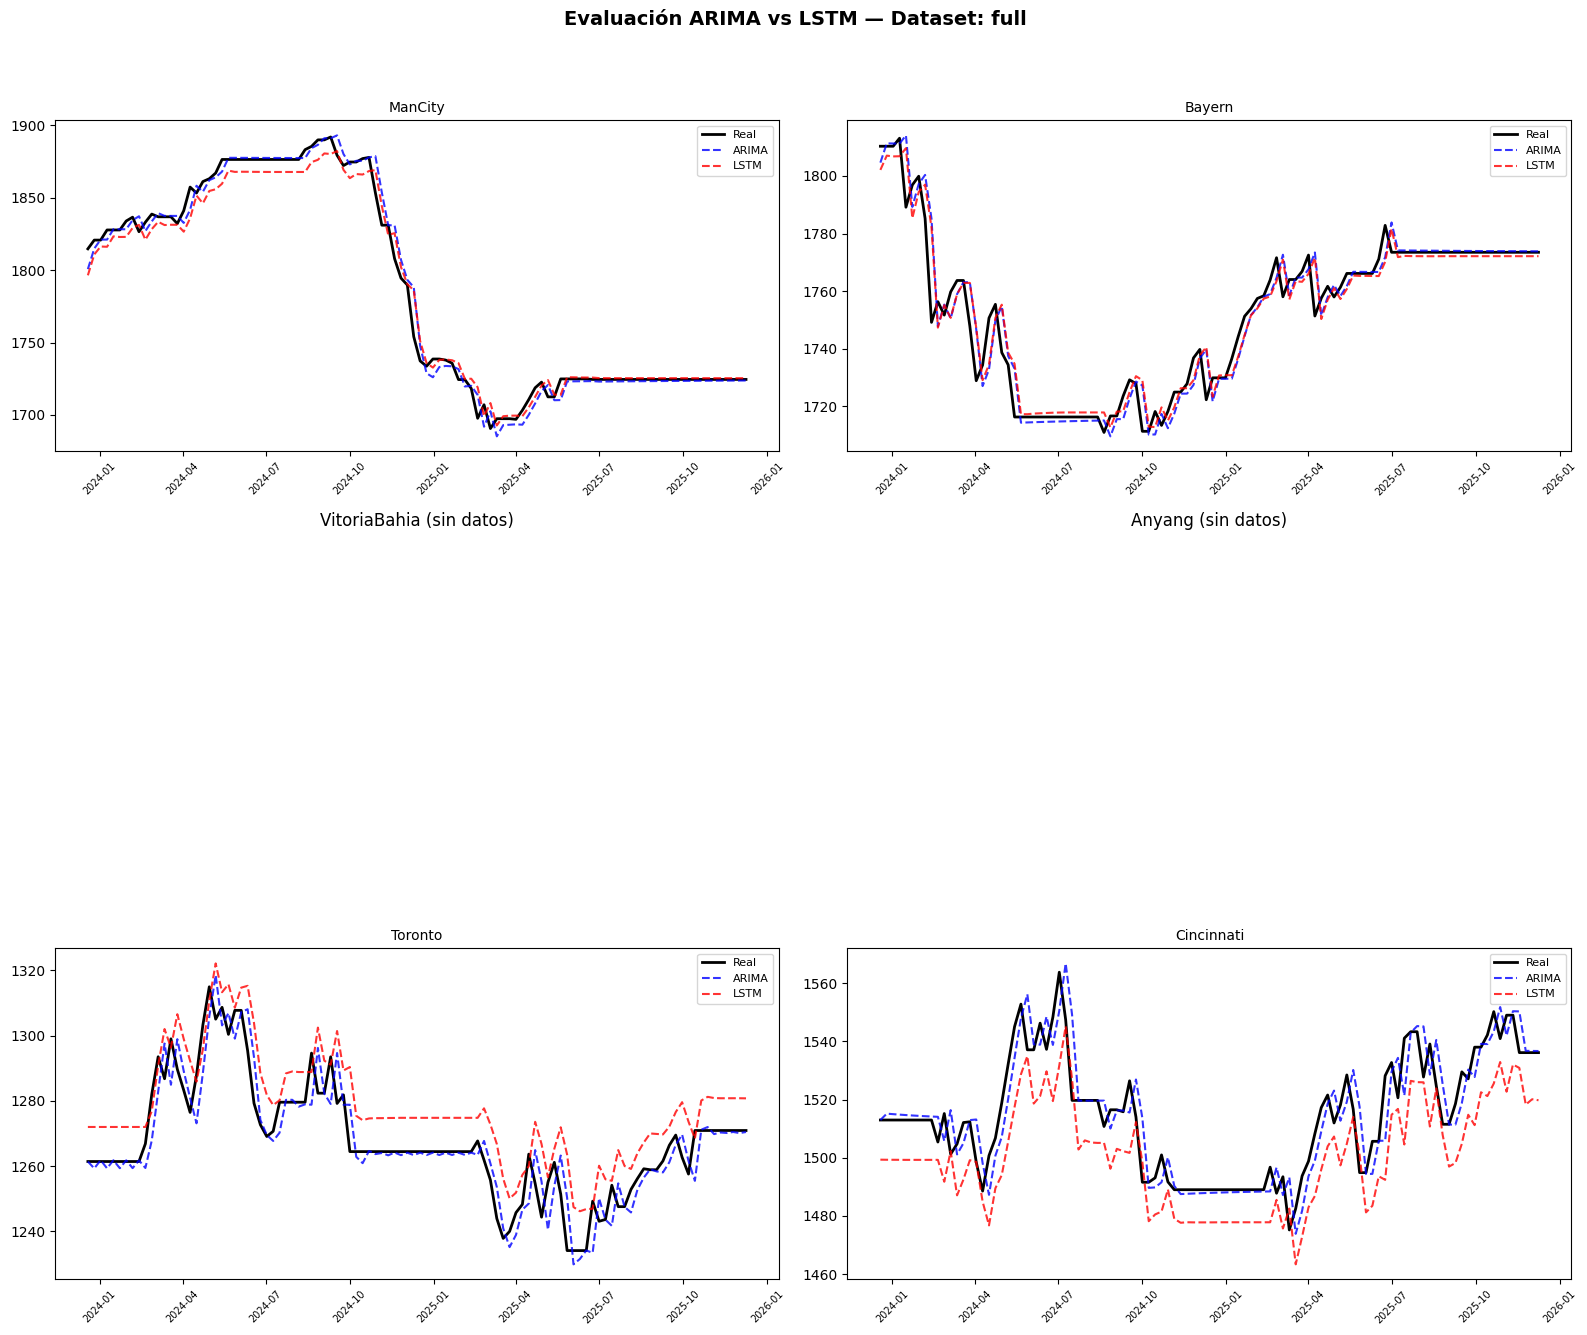

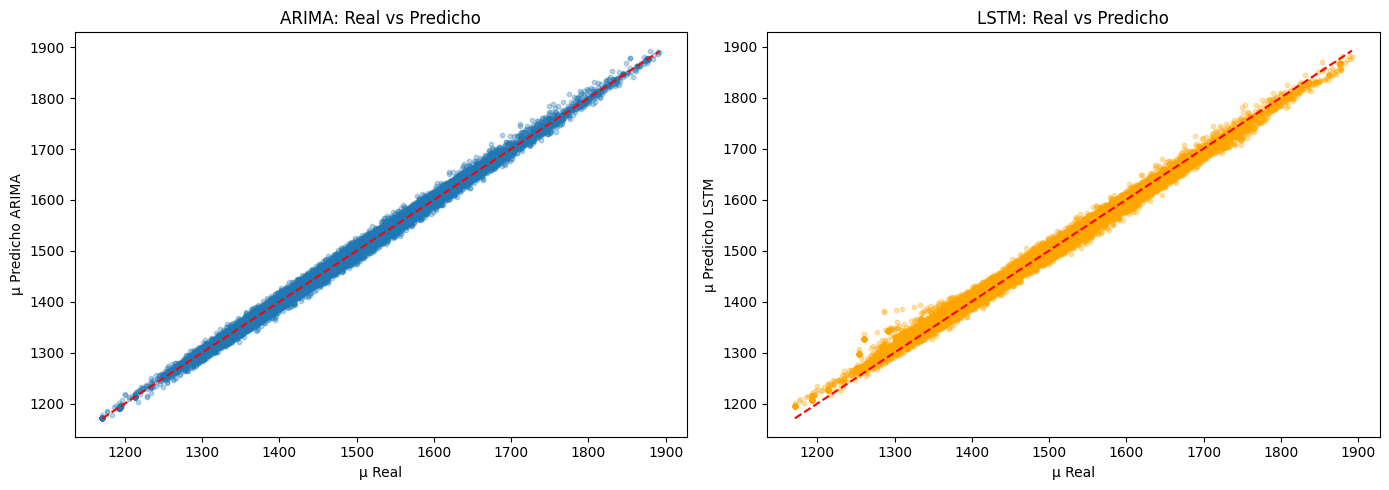

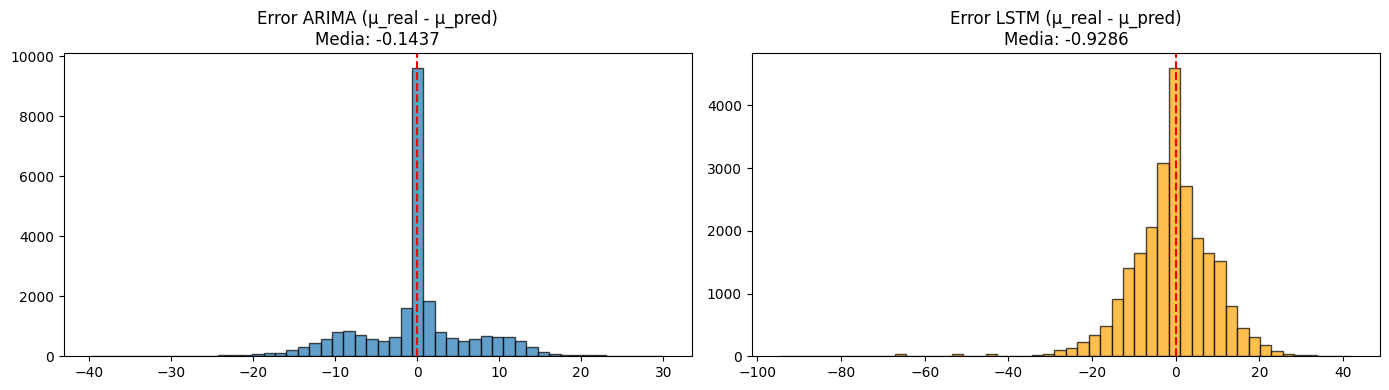

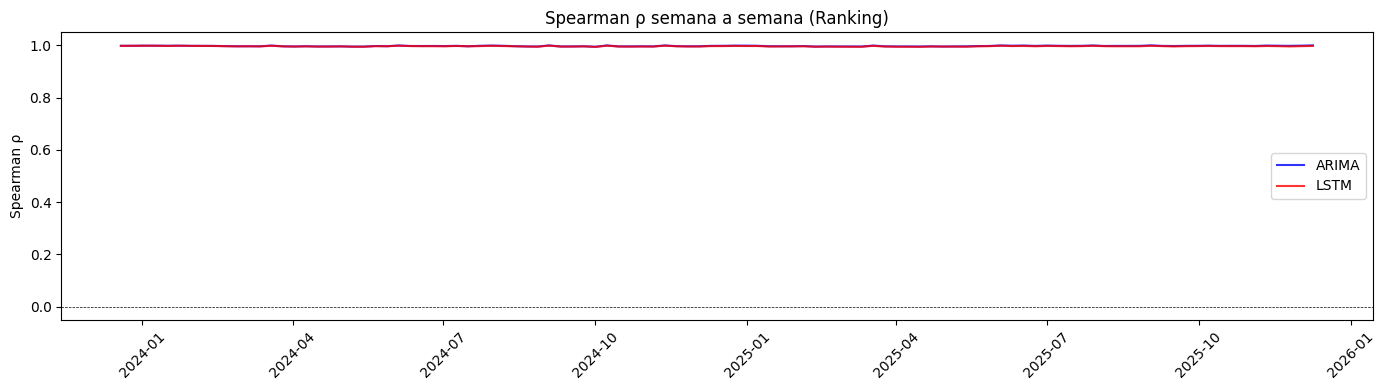


EVALUACIÓN — DATASET: LITE
Metricas Globales:
ARIMA - RMSE: 10.0592 | MAE: 4.8542
LSTM - RMSE: 11.3669 | MAE: 6.3074
RMSE (ARIMA - LSTM): -1.3077 (ARIMA gana)
LSTM gana en 103/307 equipos (33.6%)
Spearman promedio:
ARIMA: 0.9967 ± 0.0025
LSTM:  0.9964 ± 0.0025


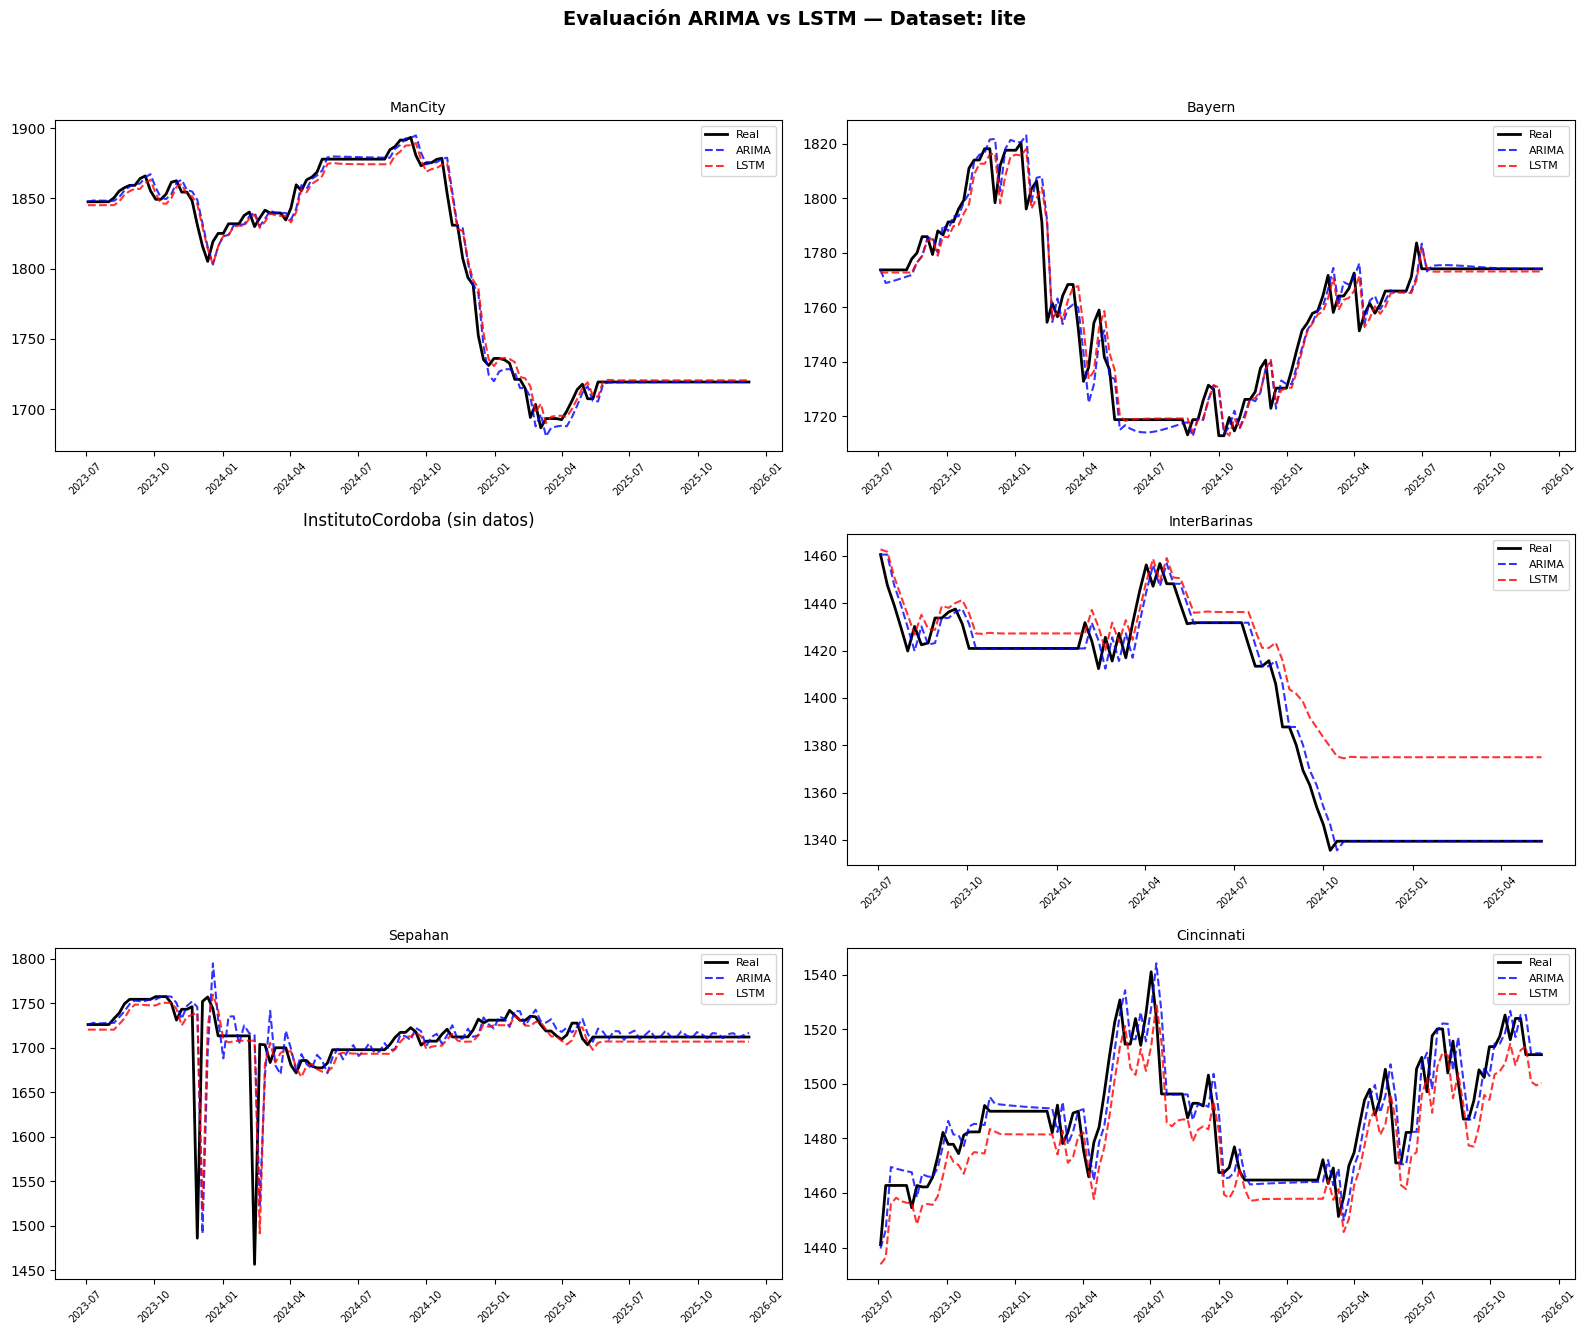

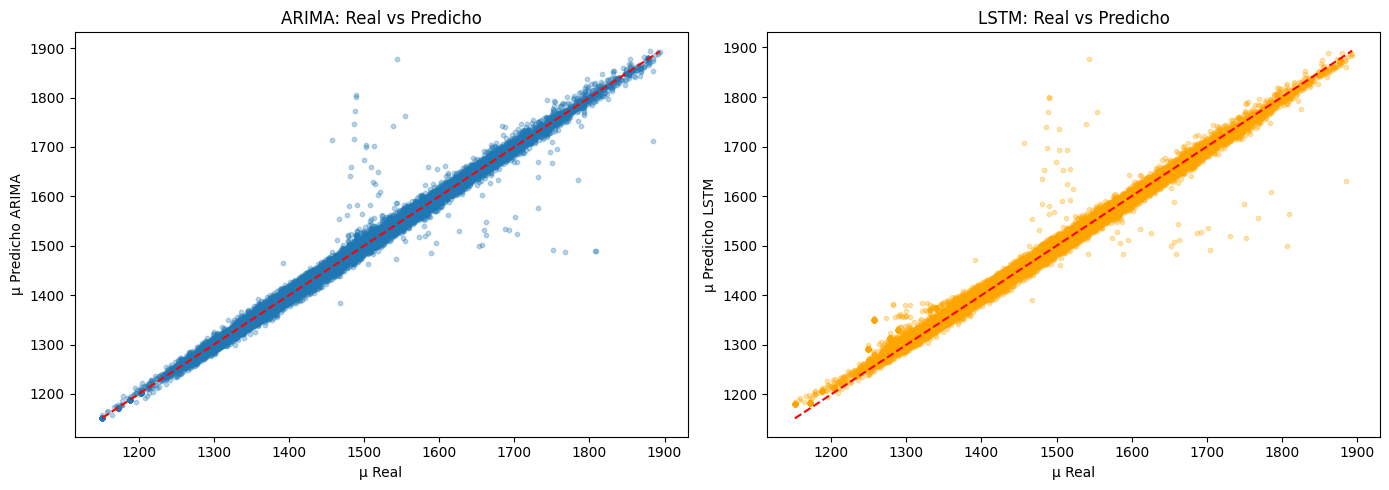

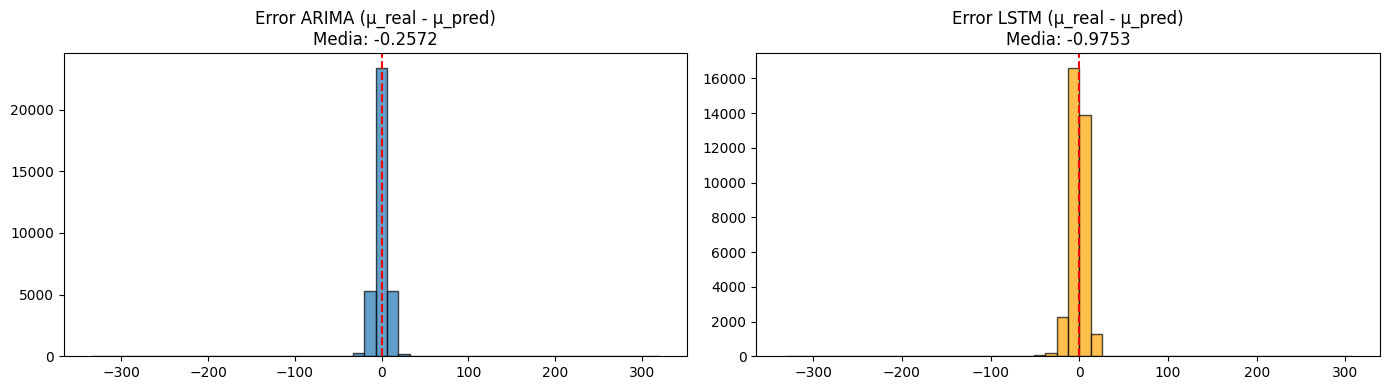

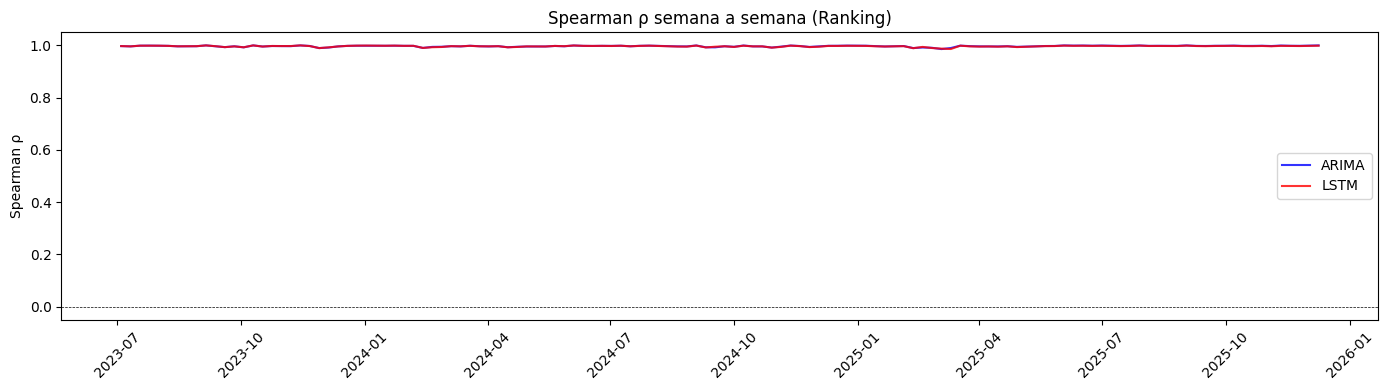

In [6]:
# ============================================================
# Celda 6 — Evaluacion y comparacion
# ============================================================

for DATASET_NAME in DATASETS:
    print(f"\n{'='*60}")
    print(f"EVALUACIÓN — DATASET: {DATASET_NAME.upper()}")
    print(f"{'='*60}")
    
    arima_results = globals()[f'arima_results_{DATASET_NAME}']
    lstm_results = globals()[f'lstm_results_{DATASET_NAME}']
    test_panel = globals()[f'test_panel_{DATASET_NAME}']
    representatives = globals()[f'representatives_{DATASET_NAME}']
    
    # Construir results_df
    rows = []
    all_teams = set(arima_results.keys()) & set(lstm_results.keys())
    
    for team in all_teams:
        arima_true = arima_results[team]['y_true']
        arima_pred = arima_results[team]['y_pred']
        lstm_true = lstm_results[team]['y_true']
        lstm_pred = lstm_results[team]['y_pred']
        
        # Unir por fecha
        common_dates = arima_true.index.intersection(lstm_true.index)
        for date in common_dates:
            if pd.isna(arima_true[date]) or pd.isna(lstm_true[date]):
                continue
            rows.append({
                'team': team,
                'date': date,
                'mu_real': arima_true[date],
                'mu_pred_arima': arima_pred[date],
                'mu_pred_lstm': lstm_pred[date]
            })
    
    if not rows:
        print("No hay datos comparables entre ARIMA y LSTM.")
        continue
    
    results_df = pd.DataFrame(rows)
    globals()[f'results_df_{DATASET_NAME}'] = results_df
    
    # Métricas globales
    rmse_arima = np.sqrt(mean_squared_error(results_df['mu_real'], results_df['mu_pred_arima']))
    mae_arima = mean_absolute_error(results_df['mu_real'], results_df['mu_pred_arima'])
    rmse_lstm = np.sqrt(mean_squared_error(results_df['mu_real'], results_df['mu_pred_lstm']))
    mae_lstm = mean_absolute_error(results_df['mu_real'], results_df['mu_pred_lstm'])
    diff_rmse = rmse_arima - rmse_lstm
    
    print(f"Metricas Globales:")
    print(f"ARIMA - RMSE: {rmse_arima:.4f} | MAE: {mae_arima:.4f}")
    print(f"LSTM - RMSE: {rmse_lstm:.4f} | MAE: {mae_lstm:.4f}")
    print(f"RMSE (ARIMA - LSTM): {diff_rmse:.4f} ({'LSTM gana' if diff_rmse > 0 else 'ARIMA gana'})")
    
    # Métricas por equipo
    team_metrics = []
    lstm_wins = 0
    for team in all_teams:
        sub = results_df[results_df['team'] == team]
        if len(sub) < 2:
            continue
        rmse_a = np.sqrt(mean_squared_error(sub['mu_real'], sub['mu_pred_arima']))
        rmse_l = np.sqrt(mean_squared_error(sub['mu_real'], sub['mu_pred_lstm']))
        team_metrics.append({'team': team, 'rmse_arima': rmse_a, 'rmse_lstm': rmse_l})
        if rmse_l < rmse_a:
            lstm_wins += 1
    
    team_metrics_df = pd.DataFrame(team_metrics)
    if len(team_metrics_df) > 0:
        prop_lstm = lstm_wins / len(team_metrics_df)
        print(f"LSTM gana en {lstm_wins}/{len(team_metrics_df)} equipos ({prop_lstm:.1%})")
    
    # Spearman semana a semana
    spearman_arima = []
    spearman_lstm = []
    
    for date in results_df['date'].unique():
        sub = results_df[results_df['date'] == date]
        if len(sub) > 1:
            rho_a, _ = spearmanr(sub['mu_real'], sub['mu_pred_arima'])
            rho_l, _ = spearmanr(sub['mu_real'], sub['mu_pred_lstm'])
            if not np.isnan(rho_a):
                spearman_arima.append(rho_a)
            if not np.isnan(rho_l):
                spearman_lstm.append(rho_l)
    
    if spearman_arima and spearman_lstm:
        print(f"Spearman promedio:")
        print(f"ARIMA: {np.mean(spearman_arima):.4f} ± {np.std(spearman_arima):.4f}")
        print(f"LSTM:  {np.mean(spearman_lstm):.4f} ± {np.std(spearman_lstm):.4f}")
    
    globals()[f'metrics_{DATASET_NAME}'] = {
        'rmse_arima': rmse_arima,
        'mae_arima': mae_arima,
        'rmse_lstm': rmse_lstm,
        'mae_lstm': mae_lstm,
        'diff_rmse': diff_rmse,
        'spearman_arima_mean': np.mean(spearman_arima) if spearman_arima else None,
        'spearman_arima_std': np.std(spearman_arima) if spearman_arima else None,
        'spearman_lstm_mean': np.mean(spearman_lstm) if spearman_lstm else None,
        'spearman_lstm_std': np.std(spearman_lstm) if spearman_lstm else None,
        'lstm_win_ratio': prop_lstm if len(team_metrics_df) > 0 else None
    }
    
    # ============================================================
    # VISUALIZACIONES
    # ============================================================
    fig, axes = plt.subplots(3, 2, figsize=(16, 14))
    fig.suptitle(f'Evaluación ARIMA vs LSTM — Dataset: {DATASET_NAME}', fontsize=14, fontweight='bold')
    
    # 1-2. Series temporales de 6 equipos representativos (3×2)
    for idx, team in enumerate(representatives[:6]):
        ax = axes[idx // 2, idx % 2]
        sub = results_df[results_df['team'] == team]
        if len(sub) == 0:
            ax.set_title(f'{team} (sin datos)')
            ax.axis('off')
            continue
        ax.plot(sub['date'], sub['mu_real'], 'k-', label='Real', linewidth=2)
        ax.plot(sub['date'], sub['mu_pred_arima'], 'b--', label='ARIMA', alpha=0.8)
        ax.plot(sub['date'], sub['mu_pred_lstm'], 'r--', label='LSTM', alpha=0.8)
        ax.set_title(team, fontsize=10)
        ax.legend(fontsize=8)
        ax.tick_params(axis='x', rotation=45, labelsize=7)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
    
    # 3. Scatter real vs predicho
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].scatter(results_df['mu_real'], results_df['mu_pred_arima'], alpha=0.3, s=10)
    axes[0].plot([results_df['mu_real'].min(), results_df['mu_real'].max()], 
                 [results_df['mu_real'].min(), results_df['mu_real'].max()], 'r--')
    axes[0].set_xlabel('μ Real')
    axes[0].set_ylabel('μ Predicho ARIMA')
    axes[0].set_title('ARIMA: Real vs Predicho')
    
    axes[1].scatter(results_df['mu_real'], results_df['mu_pred_lstm'], alpha=0.3, s=10, color='orange')
    axes[1].plot([results_df['mu_real'].min(), results_df['mu_real'].max()], 
                 [results_df['mu_real'].min(), results_df['mu_real'].max()], 'r--')
    axes[1].set_xlabel('μ Real')
    axes[1].set_ylabel('μ Predicho LSTM')
    axes[1].set_title('LSTM: Real vs Predicho')
    plt.tight_layout()
    plt.show()
    
    # 4. Histograma de errores
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    err_arima = results_df['mu_real'] - results_df['mu_pred_arima']
    err_lstm = results_df['mu_real'] - results_df['mu_pred_lstm']
    axes[0].hist(err_arima, bins=50, alpha=0.7, edgecolor='black')
    axes[0].set_title(f'Error ARIMA (μ_real - μ_pred)\nMedia: {err_arima.mean():.4f}')
    axes[0].axvline(0, color='red', linestyle='--')
    axes[1].hist(err_lstm, bins=50, alpha=0.7, edgecolor='black', color='orange')
    axes[1].set_title(f'Error LSTM (μ_real - μ_pred)\nMedia: {err_lstm.mean():.4f}')
    axes[1].axvline(0, color='red', linestyle='--')
    plt.tight_layout()
    plt.show()
    
    # 5. Serie temporal de Spearman semana a semana
    if spearman_arima and spearman_lstm:
        fig, ax = plt.subplots(figsize=(14, 4))
        dates = sorted(results_df['date'].unique())
        ax.plot(dates, spearman_arima, 'b-', label='ARIMA', alpha=0.8)
        ax.plot(dates, spearman_lstm, 'r-', label='LSTM', alpha=0.8)
        ax.axhline(0, color='black', linestyle='--', linewidth=0.5)
        ax.set_title('Spearman ρ semana a semana (Ranking)')
        ax.set_ylabel('Spearman ρ')
        ax.legend()
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

In [7]:
# %%
# ============================================================
# Celda 7 - Tabla de ranking proyectado (ultima semana de test)
# ============================================================

for DATASET_NAME in DATASETS:
    print(f"\n{'='*60}")
    print(f"RANKING FINAL — DATASET: {DATASET_NAME.upper()}")
    print(f"{'='*60}")
    
    results_df = globals().get(f'results_df_{DATASET_NAME}')
    if results_df is None or len(results_df) == 0:
        print("No hay resultados para generar ranking.")
        continue
    
    # Última semana de test con datos
    last_week = results_df['date'].max()
    last_df = results_df[results_df['date'] == last_week].copy()
    
    if len(last_df) == 0:
        print("Sin datos para la última semana.")
        continue
    
    # Ordenar por cada métrica
    last_df['pos_real'] = last_df['mu_real'].rank(ascending=False, method='min').astype(int)
    last_df['pos_arima'] = last_df['mu_pred_arima'].rank(ascending=False, method='min').astype(int)
    last_df['pos_lstm'] = last_df['mu_pred_lstm'].rank(ascending=False, method='min').astype(int)
    
    last_df['delta_pos_arima'] = last_df['pos_arima'] - last_df['pos_real']
    last_df['delta_pos_lstm'] = last_df['pos_lstm'] - last_df['pos_real']
    
    # === CAMBIO AQUI: Tomar TODOS los equipos y ordenar por mu_real ===
    ranking_completo = last_df[[
        'pos_real', 'team', 'mu_real',
        'pos_arima', 'mu_pred_arima', 'delta_pos_arima',
        'pos_lstm', 'mu_pred_lstm', 'delta_pos_lstm'
    ]].sort_values(by='mu_real', ascending=False)
    
    print(f"Semana de proyeccion: {last_week.date()}")
    print(f"Total de equipos en el ranking: {len(ranking_completo)}")
    
    # Imprimimos en pantalla solo el Top 20 para no saturar la salida del notebook
    print("\n--- Vista previa (Top 20) ---")
    print(ranking_completo.head(20).to_string(index=False))
    
    # Exportar CSV con TODOS los equipos
    csv_path = f"{BASE_DATA_DIR}/ranking_proyectado_final_{DATASET_NAME}.csv"
    ranking_completo.to_csv(csv_path, index=False)
    print(f"\nCSV guardado con TODOS los {len(ranking_completo)} equipos en: {csv_path}")
    
    # Guardar en memoria global
    globals()[f'ranking_completo_{DATASET_NAME}'] = ranking_completo


RANKING FINAL — DATASET: FULL
Semana de proyeccion: 2025-12-09
Total de equipos en el ranking: 214

--- Vista previa (Top 20) ---
 pos_real       team     mu_real  pos_arima  mu_pred_arima  delta_pos_arima  pos_lstm  mu_pred_lstm  delta_pos_lstm
        1        PSG 1807.348370          1    1808.067953                0         1   1800.868164               0
        2    AlHilal 1788.855312          2    1789.724365                0         2   1780.751221               0
        3     Bayern 1773.511765          3    1773.839444                0         3   1772.156494               0
        4 RealMadrid 1766.355138          4    1767.136430                0         4   1763.284424               0
        5  Liverpool 1749.680306          5    1749.679376                0         5   1746.077271               0
        6 InterMilan 1744.920874          6    1745.965614                0         6   1730.885620               0
        7    ManCity 1724.548311          7    1723.80035

In [8]:
# ============================================================
# Celda 8 - Exportacion y limitaciones declaradas
# ============================================================

for DATASET_NAME in DATASETS:
    print(f"\n{'='*60}")
    print(f"EXPORTACIÓN — DATASET: {DATASET_NAME.upper()}")
    print(f"{'='*60}")
    
    results_df = globals().get(f'results_df_{DATASET_NAME}')
    metrics = globals().get(f'metrics_{DATASET_NAME}')
    
    if results_df is not None and len(results_df) > 0:
        # CSV maestro
        csv_path = f"{BASE_DATA_DIR}/proyecciones_arima_lstm_{DATASET_NAME}.csv"
        results_df.to_csv(csv_path, index=False)
        print(f"Proyecciones guardadas: {csv_path}")
    
    if metrics is not None:
        # JSON métricas
        json_path = f"{BASE_DATA_DIR}/metricas_proyeccion_{DATASET_NAME}.json"
        with open(json_path, 'w') as f:
            json.dump(metrics, f, indent=2, default=str)
        print(f"Métricas guardadas: {json_path}")

# ============================================================
# BLOQUE DE LIMITACIONES (listo para copiar a LaTeX)
# ============================================================

limitaciones = """
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
% LIMITACIONES DEL MODELO DE PROYECCIÓN ARIMA + LSTM
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%

\\begin{itemize}
    \\item \\textbf{Baja frecuencia:} Aproximadamente 400 puntos en 8 años, 
    insuficiente para capturar estacionalidad anual robusta.
    
    \\item \\textbf{Huecos estructurales:} El verano europeo ($\\sim$10--12 semanas) 
    genera tramos planos por forward-fill. La pandemia COVID-19 (Mar--Jun 2020) 
    rompe series con gaps $>$ 12 semanas.
    
    \\item \\textbf{Calendarios asincrónicos:} Ligas anuales (MLS, J1) vs. 
    temporadas europeas crean un panel no sincronizado donde el ``estado'' de 
    los equipos evoluciona a ritmos distintos.
    
    \\item \\textbf{LSTM global:} Asume patrones transferibles entre equipos de 
    distintas ligas, lo cual puede no ser válido.
    
    \\item \\textbf{Sin covariables:} Solo se utiliza $\\mu$ histórico. No se 
    incorpora información de mercado de fichajes, lesiones, fixture ni 
    condición de localía.
    
    \\item \\textbf{Ranking indirecto:} Se predice $\\mu$ continuo; la conversión 
    a posición ordinal introduce ruido adicional en la zona media del ranking.
    
    \\item \\textbf{Split 70/30:} El conjunto de test incluye el parón estival 
    europeo 2025, donde muchos equipos tienen $\\mu$ estático por inactividad, 
    sesgando el error de ARIMA hacia cero para esos equipos.
\\end{itemize}

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
"""

print(limitaciones)

# Guardar también como archivo de texto
with open(f"{BASE_DATA_DIR}/limitaciones_proyeccion.txt", "w") as f:
    f.write(limitaciones)
print(f"\n Limitaciones guardadas en: {BASE_DATA_DIR}/limitaciones_proyeccion.txt")

print("\n" + "="*60)
print("NOTEBOOK COMPLETADO PARA LOS DATASETS")
print("="*60)


EXPORTACIÓN — DATASET: FULL


Proyecciones guardadas: /content/drive/MyDrive/TEG02-2025Arellano/Data/proyecciones_arima_lstm_full.csv
Métricas guardadas: /content/drive/MyDrive/TEG02-2025Arellano/Data/metricas_proyeccion_full.json

EXPORTACIÓN — DATASET: LITE
Proyecciones guardadas: /content/drive/MyDrive/TEG02-2025Arellano/Data/proyecciones_arima_lstm_lite.csv
Métricas guardadas: /content/drive/MyDrive/TEG02-2025Arellano/Data/metricas_proyeccion_lite.json

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
% LIMITACIONES DEL MODELO DE PROYECCIÓN ARIMA + LSTM
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%

\begin{itemize}
    \item \textbf{Baja frecuencia:} Aproximadamente 400 puntos en 8 años, 
    insuficiente para capturar estacionalidad anual robusta.
    
    \item \textbf{Huecos estructurales:} El verano europeo ($\sim$10--12 semanas) 
    genera tramos planos por forward-fill. La pandemia COVID-19 (Mar--Jun 2020) 
    rompe series con gaps $>$ 12 

In [9]:
# %%
# ============================================================
# Celda 9 — FORECASTING PURO: proyección a 52 semanas (2026)
# ============================================================

FORECAST_WEEKS = 52  # 1 año hacia adelante
TIMESTEPS = 8        # Mismo valor usado en entrenamiento

# Diccionarios para almacenar los forecasts
arima_forecasts_all = {}
lstm_forecasts_all = {}

import signal
class TimeoutException(Exception): pass
def timeout_handler(signum, frame): raise TimeoutException()

for DATASET_NAME in DATASETS:
    print(f"\n{'='*60}")
    print(f"🔮 FORECASTING — DATASET: {DATASET_NAME.upper()}")
    print(f"{'='*60}")
    
    # Recuperar el panel completo (ya filtrado y con ffill)
    panel = globals()[f'panel_{DATASET_NAME}']
    
    # Fechas futuras: 52 semanas a partir de la última fecha del panel
    last_date = panel.index[-1]
    future_dates = pd.date_range(
        start=last_date + pd.Timedelta(weeks=1),
        periods=FORECAST_WEEKS,
        freq='W-MON'
    )
    print(f"Última fecha histórica: {last_date.date()}")
    print(f"Proyección: {future_dates[0].date()} → {future_dates[-1].date()}")
    
    teams = panel.columns.tolist()
    
    # ==========================================
    # --- ARIMA: reentrenar sobre toda la serie ---
    # ==========================================
    print("\n⏳ Entrenando ARIMA sobre toda la serie...")
    arima_forecasts = {}
    
    for idx, team in enumerate(teams):
        if idx > 0 and idx % 50 == 0:
            print(f"   ...ARIMA procesados {idx}/{len(teams)} equipos")
            
        try:
            # CORRECCIÓN: Usar 'panel' en lugar de 'df'
            train_series = panel[team].dropna() 
            
            if len(train_series) < 24 or train_series.std() == 0:
                continue
                
            model = auto_arima(
                train_series.values, 
                seasonal=False, 
                stepwise=True, 
                suppress_warnings=True,
                error_action='ignore',
                max_p=3, max_q=3, max_d=2, max_order=5,
                trace=False
            )
            
            # Forzar predicción a lista estándar
            preds = list(model.predict(n_periods=FORECAST_WEEKS))
            arima_forecasts[team] = preds

        except Exception as e:
            print(f"⚠️ Error ARIMA en {team}: {e}")

    print(f"✅ ARIMA forecasts generados para {len(arima_forecasts)} equipos.")
    arima_forecasts_all[DATASET_NAME] = arima_forecasts
    
    # Exportar ARIMA
    df_forecast_arima = pd.DataFrame(arima_forecasts, index=future_dates)
    path_arima = f"{BASE_DATA_DIR}/forecast_arima_52w_{DATASET_NAME}.csv"
    df_forecast_arima.to_csv(path_arima)
    
    # ==========================================
    # --- LSTM: reentrenar sobre toda la serie ---
    # ==========================================
    print("\n⏳ Entrenando LSTM sobre toda la serie...")
    
    X_full, y_full = [], []
    scalers_full = {}
    skipped_teams_lstm = []

    for team in teams: 
        try:
            serie = panel[team].dropna()
            if len(serie) < TIMESTEPS + 1:
                skipped_teams_lstm.append(team)
                continue
                    
            vals = serie.values.reshape(-1, 1)
            scaler = StandardScaler()
            scaler.fit(vals)
            scalers_full[team] = scaler
                    
            scaled = scaler.transform(vals)
                    
            for i in range(len(scaled) - TIMESTEPS):
                X_full.append(scaled[i:i+TIMESTEPS])
                y_full.append(scaled[i+TIMESTEPS])
        except Exception as e:
            print(f"⚠️ Error al preparar datos LSTM en {team}: {e}")

    X_full = np.array(X_full)
    y_full = np.array(y_full)
    print(f"Secuencias totales para LSTM: {X_full.shape}")
    
    if len(X_full) == 0:
        print("❌ No hay datos suficientes para LSTM.")
        lstm_forecasts_all[DATASET_NAME] = {}
        continue
    
    # Arquitectura
    model_lstm = Sequential([
        LSTM(64, input_shape=(TIMESTEPS, 1)),
        Dropout(0.2),
        Dense(1)
    ])
    model_lstm.compile(optimizer='adam', loss='mse')
    
    es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6
    )
    
    model_lstm.fit(
        X_full, y_full,
        validation_split=0.1,
        epochs=100,
        batch_size=32,
        callbacks=[es, reduce_lr],
        verbose=1
    )
    
    # Generar forecasts recursivos por equipo
    lstm_forecasts = {}
    for idx, team in enumerate(teams):
        if idx > 0 and idx % 50 == 0:
            print(f"   ...LSTM proyecciones generadas para {idx}/{len(teams)} equipos")
            
        if team not in scalers_full:
            continue
            
        scaler = scalers_full[team]
        serie = panel[team].dropna()
        if len(serie) < TIMESTEPS:
            continue
        
        # CORRECCIÓN: Indentación ajustada dentro del bucle
        vals = serie.values.reshape(-1, 1)
        scaled = scaler.transform(vals)
        last_window = scaled[-TIMESTEPS:].reshape(1, TIMESTEPS, 1)
            
        forecast_scaled = []
        for _ in range(FORECAST_WEEKS):
            # CORRECCIÓN: Llamada directa al modelo, evita overhead brutal en GPU
            pred = model_lstm(last_window, training=False).numpy()[0, 0]
            forecast_scaled.append(pred)
            
            # Desplazar ventana
            last_window = np.roll(last_window, -1, axis=1)
            last_window[0, -1, 0] = pred
            
        forecast_vals = scaler.inverse_transform(
            np.array(forecast_scaled).reshape(-1, 1)
        ).flatten()
        
        lstm_forecasts[team] = forecast_vals
    
    print(f"✅ LSTM forecasts generados para {len(lstm_forecasts)} equipos.")
    lstm_forecasts_all[DATASET_NAME] = lstm_forecasts
    
    # Exportar LSTM
    df_lstm = pd.DataFrame(lstm_forecasts, index=future_dates)
    path_lstm = f"{BASE_DATA_DIR}/forecast_lstm_52w_{DATASET_NAME}.csv"
    df_lstm.to_csv(path_lstm)

print("\n" + "="*60)
print("🚀 FORECASTING COMPLETADO Y EXPORTADO PARA LOS DATASETS")
print("="*60)


🔮 FORECASTING — DATASET: FULL
Última fecha histórica: 2025-12-09
Proyección: 2025-12-22 → 2026-12-14

⏳ Entrenando ARIMA sobre toda la serie...


   ...ARIMA procesados 50/334 equipos
   ...ARIMA procesados 100/334 equipos
   ...ARIMA procesados 150/334 equipos
   ...ARIMA procesados 200/334 equipos
   ...ARIMA procesados 250/334 equipos
   ...ARIMA procesados 300/334 equipos
✅ ARIMA forecasts generados para 334 equipos.

⏳ Entrenando LSTM sobre toda la serie...
Secuencias totales para LSTM: (79614, 8, 1)
Epoch 1/100
2240/2240 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - loss: 0.0513 - val_loss: 0.0401 - learning_rate: 0.0010
Epoch 2/100
2240/2240 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - loss: 0.0392 - val_loss: 0.0398 - learning_rate: 0.0010
Epoch 3/100
2240/2240 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - loss: 0.0387 - val_loss: 0.0393 - learning_rate: 0.0010
Epoch 4/100
2240/2240 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - loss: 0.0388 - val_loss: 0.0395 - learning_rate: 0.0010
Epoch 5/100
2240/2240 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - loss: 0.0388 - val_loss: 0.0394 - learning_rate: 0.0010
Epoch 6/100
2240/2240 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - loss: 0

In [ ]:
# ===== TRAZABILIDAD - FIN =====

print("="*70)
print("FIN DE EJECUCIÓN")
print("Fecha y hora UTC:", datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S"))
print("Fecha y hora local:", datetime.now(tz_caracas).strftime("%Y-%m-%d %H:%M:%S"))
print("="*70)

FIN DE EJECUCIÓN
Fecha y hora UTC: 2026-09-17 01:09:55
Fecha y hora local: 2026-09-16 21:09:55
